In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
import urllib.request
import zipfile
import io
import pandas as pd

# URL to the Student Performance Dataset zip file on the UCI Repository
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

# Download and extract the zip archive in-memory
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(req) as response:
    zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
    # The actual data file is nested inside 'student.zip'
    with zip_file.open('student.zip') as nested_zip_bytes:
        with zipfile.ZipFile(io.BytesIO(nested_zip_bytes.read())) as nested_zip:
            with nested_zip.open('student-mat.csv') as f:
                df = pd.read_csv(f, sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
print("Number of rows and columns:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and missing values:")
df.info()

print("\nStatistical summary:")
df.describe()

Number of rows and columns:
(395, 33)

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 1

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


In [11]:

# Step 5: Identify columns with missing values

missing_values = df.isnull().sum()

missing_summary = missing_values[missing_values > 0]

print("Columns containing missing values:")
print(missing_summary)

print("\nTotal missing values:", df.isnull().sum().sum())


Columns containing missing values:
Series([], dtype: int64)

Total missing values: 0


In [12]:

# Step 6: Display rows containing missing values

rows_with_missing = df[df.isnull().any(axis=1)]

print("Number of rows containing missing values:",
      len(rows_with_missing))

display(rows_with_missing)


Number of rows containing missing values: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3


In [13]:

# Step 7: Check duplicate records

print("Duplicate rows:", df.duplicated().sum())

print("Original dataset shape:", df.shape)


Duplicate rows: 0
Original dataset shape: (395, 33)


In [14]:

# Step 8: Check data types

print(df.dtypes)


school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nursery       object
higher        object
internet      object
romantic      object
famrel         int64
freetime       int64
goout          int64
Dalc           int64
Walc           int64
health         int64
absences       int64
G1             int64
G2             int64
G3             int64
dtype: object


In [15]:

# Step 9: Validate the final grade

print("Minimum final grade:", df["G3"].min())
print("Maximum final grade:", df["G3"].max())

invalid_grades = df[
    (df["G3"] < 0) | (df["G3"] > 20)
]

print("Number of invalid final grades:", len(invalid_grades))


Minimum final grade: 0
Maximum final grade: 20
Number of invalid final grades: 0


In [16]:

# Step 10: Confirm data quality

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData quality check completed.")


Dataset shape: (395, 33)
Missing values: 0
Duplicate rows: 0

Data quality check completed.


In [17]:

# Step 11: Create a clean working copy

df_clean = df.copy()

# Save the cleaned dataset
df_clean.to_csv("student_performance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Cleaned dataset shape:", df_clean.shape)


Cleaned dataset saved successfully!
Cleaned dataset shape: (395, 33)


In [18]:
from google.colab import files
files.download("student_performance_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

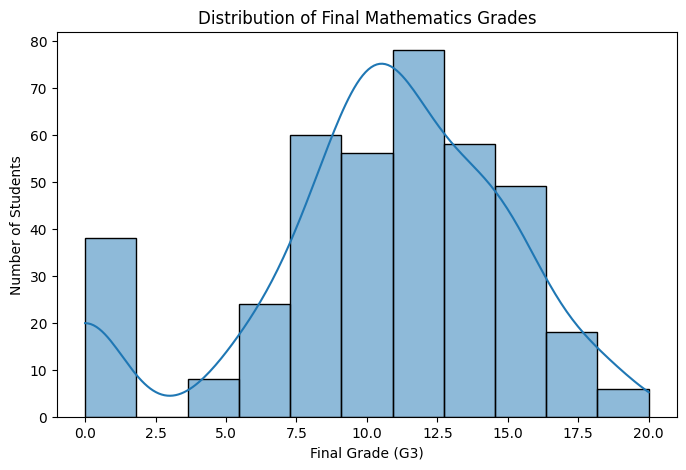

In [19]:

# Step 12: Visualize final mathematics grades

plt.figure(figsize=(8, 5))

sns.histplot(df_clean["G3"], bins=11, kde=True)

plt.title("Distribution of Final Mathematics Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")

plt.show()


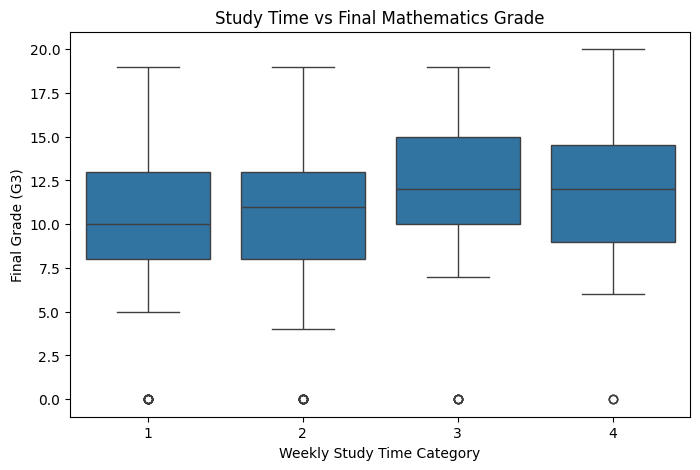

In [20]:

# Step 13: Study time versus final grades

plt.figure(figsize=(8, 5))

sns.boxplot(data=df_clean, x="studytime", y="G3")

plt.title("Study Time vs Final Mathematics Grade")
plt.xlabel("Weekly Study Time Category")
plt.ylabel("Final Grade (G3)")

plt.show()


In [21]:

# Step 14: Summary statistics

print("Average final grade:", df_clean["G3"].mean())
print("Median final grade:", df_clean["G3"].median())
print("Highest final grade:", df_clean["G3"].max())
print("Lowest final grade:", df_clean["G3"].min())


Average final grade: 10.415189873417722
Median final grade: 11.0
Highest final grade: 20
Lowest final grade: 0


Initial Data Analysis: The Student Performance dataset contains 395 student records and 33 columns. The average final mathematics grade (G3) is approximately 10.42 out of 20, while the median is 11. The highest observed grade is 20 and the lowest is 0. These descriptive statistics provide an initial understanding of student performance before further analysis and model development.

In [22]:

# Step 15: Examine relationships between numerical columns

selected_columns = [
    "studytime",
    "failures",
    "absences",
    "G1",
    "G2",
    "G3"
]

correlation = df_clean[selected_columns].corr()

print(correlation["G3"].sort_values(ascending=False))


G3           1.000000
G2           0.904868
G1           0.801468
studytime    0.097820
absences     0.034247
failures    -0.360415
Name: G3, dtype: float64


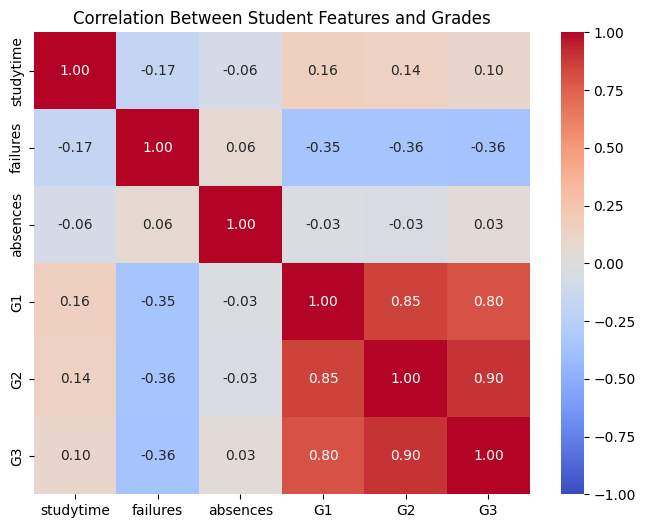

In [23]:

# Step 16: Correlation heatmap

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Student Features and Grades")
plt.show()


This graph just identify about which variables have stronger relationships with final grades

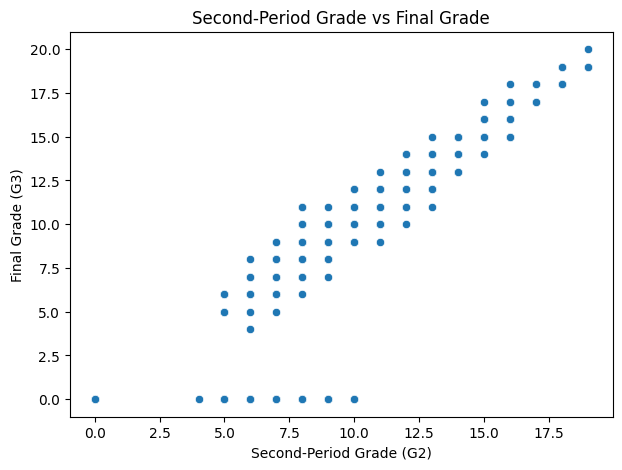

In [24]:

# Step 17: Previous grade versus final grade

plt.figure(figsize=(7, 5))

sns.scatterplot(data=df_clean, x="G2", y="G3")

plt.title("Second-Period Grade vs Final Grade")
plt.xlabel("Second-Period Grade (G2)")
plt.ylabel("Final Grade (G3)")
plt.show()


This graph visualization helps us how final grades vary with second-period grades

Exploratory Data Analysis (EDA): The Correlation analysis was perform to investigate the relation between student characteristics and final mathematics grades.

The strongest positive relationship among the selected features was observed for second period grade (G2), with a correlation coefficient of approximately 0.905. The first period grade (G1) also show a strong positive relationship with (G3),with a coefficient of approximately 0.801.

Previous calss failures showed a negative relationship with final grades, with a correlation coefficient of approximately -0.360. Study time had a weak positive correlation of approximately o.098, while absences had a very weak positive correlation of approximately 0.034.

These findings help identify potentially useful features for model development. However, correlation alone does not establish causation, and usefulness of each feature must be assessed in the context of intended prediction task.

In [6]:
# Step 18: Select features and target
import pandas as pd
import urllib.request
import zipfile
import io
import os

# Safely load the dataset dynamically if memory/disk has been reset
if 'df_clean' not in globals():
    if os.path.exists('student_performance_cleaned.csv'):
        df_clean = pd.read_csv('student_performance_cleaned.csv')
    else:
        print("Data not found. Re-downloading and extracting the dataset...")
        url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
        req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as response:
            zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
            with zip_file.open('student.zip') as nested_zip_bytes:
                with zipfile.ZipFile(io.BytesIO(nested_zip_bytes.read())) as nested_zip:
                    with nested_zip.open('student-mat.csv') as f:
                        df_clean = pd.read_csv(f, sep=";")
        # Re-save the clean dataset locally
        df_clean.to_csv("student_performance_cleaned.csv", index=False)

features = [
    "G1",
    "G2",
    "studytime",
    "absences",
    "failures"
]

X = df_clean[features]
y = df_clean["G3"]

print("Input features:")
print(X.head())

print("\nTarget values:")
print(y.head())

print("\nFeature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

Input features:
   G1  G2  studytime  absences  failures
0   5   6          2         6         0
1   5   5          2         4         0
2   7   8          2        10         3
3  15  14          3         2         0
4   6  10          2         4         0

Target values:
0     6
1     6
2    10
3    15
4    10
Name: G3, dtype: int64

Feature dataset shape: (395, 5)
Target dataset shape: (395,)


In [9]:
# Step 19: Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 316
Testing records: 79


In [10]:

# Step 20: Train the Random Forest model

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [11]:

# Step 21: Predict the test grades

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 3))


MAE: 1.06
RMSE: 1.65
R-squared: 0.868


MAE = 1.06: On average, predictions differ from the actual final grade by about 1.06 marks on the 0–20 scale.



RMSE = 1.65: Larger prediction errors affect this metric more strongly than smaller ones.



R² = 0.868: The model explains approximately 86.8% of the variation in final grades in your test set. This is a strong result for this test split, though it doesn't guarantee the same performance on new students.

In [12]:

# Step 22: Compare actual and predicted grades

results = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": np.round(y_pred, 2)
})

display(results.head(10))


,Actual Grade,Predicted Grade
0,10,8.32
1,12,11.49
2,5,6.76
3,10,9.49
4,9,9.20
5,13,13.47
6,18,18.91
7,6,7.10
8,0,4.22
9,14,12.91


In [14]:
def predict_student_performance(G1, G2, studytime, failures, absences):
    # Create dataframe
    student = pd.DataFrame([{
        "G1": G1,
        "G2": G2,
        "studytime": studytime,
        "failures": failures,
        "absences": absences
    }])

    # Reorder the columns to match the exact order used during model.fit()
    feature_order = ["G1", "G2", "studytime", "absences", "failures"]
    student = student[feature_order]

    prediction = model.predict(student)[0]

    # Keep the predicted grade within the valid 0–20 range
    prediction = max(0, min(20, prediction))

    return round(float(prediction), 2)


predicted_grade = predict_student_performance(
    G1=10,
    G2=12,
    studytime=2,
    failures=0,
    absences=4
)

print("Predicted Final Grade:", predicted_grade, "/ 20")

Predicted Final Grade: 11.97 / 20


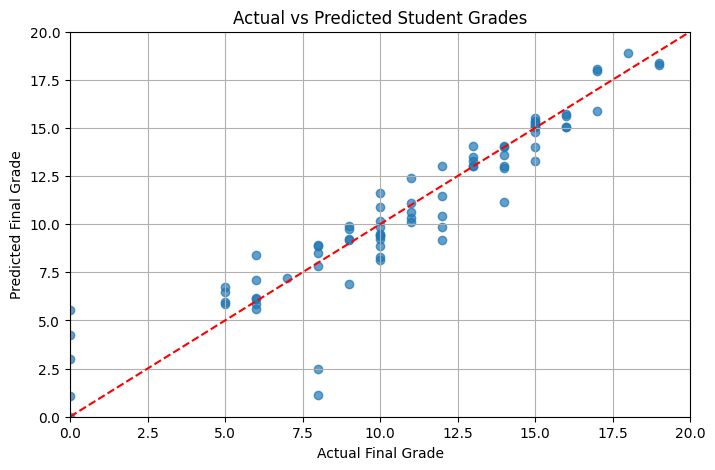

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction reference line
plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(True)
plt.show()

Visualize actual grades vs predicted grades.

Blue dots: Each dot represents a student in your test dataset.



X-axis: The student's actual final grade (G3).



Y-axis: The grade predicted by your model.



Red dashed line: The ideal prediction line, where predicted grade equals actual grade.

Most blue dots are relatively close to the red line, indicating that model predicts many students' grades reasonably well. However, a few dots are farther away, especially for some students with low actual grades. These represent larger prediction errors.

Model Evaluation and Visualization

A Random Forest Regressor was trained to predict students' final mathematics grades using first-period grade (G1), second-period grade (G2), study-time category, previous failures, and absences.

The dataset was divided into training and testing sets, with 316 records used for training and 79 records used for testing.

The model achieved a Mean Absolute Error (MAE) of 1.06, Root Mean Squared Error (RMSE) of 1.65, and R² score of 0.868. These results indicate that the model performed well on the selected test set.

The actual-versus-predicted scatter plot shows that most predictions are reasonably close to the ideal prediction line, although some larger errors remain.

The model can be used to estimate a student's final mathematics grade based on the selected input features.

In [4]:
import joblib
import os
import pandas as pd
from sklearn.ensemble import RandomForestRegressor

# Self-healing: If the notebook kernel reset and 'model' is missing, retrain it dynamically
if 'model' not in globals():
    print("Model not found in memory. Re-loading data and retraining model...")

    # Ensure we have our clean dataset loaded
    if 'df_clean' not in globals():
        if os.path.exists('student_performance_cleaned.csv'):
            df_clean = pd.read_csv('student_performance_cleaned.csv')
        else:
            import urllib.request
            import zipfile
            import io
            print("Data file not found. Re-downloading dataset...")
            url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req) as response:
                zip_file = zipfile.ZipFile(io.BytesIO(response.read()))
                with zip_file.open('student.zip') as nested_zip_bytes:
                    with zipfile.ZipFile(io.BytesIO(nested_zip_bytes.read())) as nested_zip:
                        with nested_zip.open('student-mat.csv') as f:
                            df_clean = pd.read_csv(f, sep=";")
            df_clean.to_csv("student_performance_cleaned.csv", index=False)

    # Ensure we have our training split
    if 'X_train' not in globals() or 'y_train' not in globals():
        from sklearn.model_selection import train_test_split
        features = ["G1", "G2", "studytime", "absences", "failures"]
        X = df_clean[features]
        y = df_clean["G3"]
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

    model = RandomForestRegressor(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

# Save the model
joblib.dump(model, "student_performance_model.pkl")
print("Model saved successfully to 'student_performance_model.pkl'!")

Model saved successfully to 'student_performance_model.pkl'!


In [5]:

from google.colab import files

files.download("student_performance_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:

import joblib

loaded_model = joblib.load("student_performance_model.pkl")

print("Model loaded successfully!")


Model loaded successfully!


In [8]:
sample_student = pd.DataFrame([{
    "G1": 10,
    "G2": 12,
    "studytime": 2,
    "failures": 0,
    "absences": 4
}])

# Reorder columns to match the model training features order
feature_order = ["G1", "G2", "studytime", "absences", "failures"]
sample_student = sample_student[feature_order]

prediction = loaded_model.predict(sample_student)[0]

print("Predicted Final Grade:", round(float(prediction), 2), "/ 20")

Predicted Final Grade: 11.97 / 20


In [14]:
import ipywidgets as widgets
import pandas as pd
from IPython.display import display, clear_output

# Use the exact feature order from model training
features = ["G1", "G2", "studytime", "absences", "failures"]
g1_input = widgets.IntSlider(value=10, min=0, max=20, description="G1:")
g2_input = widgets.IntSlider(value=12, min=0, max=20, description="G2:")

studytime_input = widgets.Dropdown(
    options=[1, 2, 3, 4], value=2, description="Study time:"
)

failures_input = widgets.Dropdown(
    options=[0, 1, 2, 3], value=0, description="Failures:"
)

absences_input = widgets.IntSlider(
    value=4, min=0, max=50, description="Absences:"
)

predict_button = widgets.Button(
    description="Predict Final Grade",
    button_style="success"
)

output = widgets.Output()

def on_predict_clicked(button):
    with output:
        clear_output(wait=True)

        # Standardizing indentation to exactly 8 spaces here
        student = pd.DataFrame([{
            "G1": g1_input.value,
            "G2": g2_input.value,
            "studytime": studytime_input.value,
            "absences": absences_input.value,
            "failures": failures_input.value
        }])

        student = student[features]

        grade = loaded_model.predict(student)[0]
        grade = max(0, min(20, grade))

        print(f"Predicted Final Grade: {grade:.2f} / 20")

predict_button.on_click(on_predict_clicked)

display(
    g1_input,
    g2_input,
    studytime_input,
    failures_input,
    absences_input,
    predict_button,
    output
)

IntSlider(value=10, description='G1:', max=20)

IntSlider(value=12, description='G2:', max=20)

Dropdown(description='Study time:', index=1, options=(1, 2, 3, 4), value=2)

Dropdown(description='Failures:', options=(0, 1, 2, 3), value=0)

IntSlider(value=4, description='Absences:', max=50)

Button(button_style='success', description='Predict Final Grade', style=ButtonStyle())

Output()

In [11]:
print("Expected features:", loaded_model.feature_names_in_)
print("Interface features:", features)

Expected features: ['G1' 'G2' 'studytime' 'absences' 'failures']
Interface features: ['G1', 'G2', 'studytime', 'failures', 'absences']
